# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Muhammad Fardan Hafidz | 5054251021 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k\$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
import os
import warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Konfigurasi tampilan grafik
sns.set_theme(style="whitegrid")
plt.rcParams["figure.autolayout"] = True
print("Seluruh library berhasil diimpor dengan sukses.")


Seluruh library berhasil diimpor dengan sukses.


In [2]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
df = pd.read_csv("Mall_Customers.csv")

print("=== 5 Baris Pertama Dataset ===")
display(df.head())

print(f"\nDimensi Dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

print("\n=== Informasi Tipe Data Kolom ===")
df.info()

print("\n=== Statistik Deskriptif ===")
display(df.describe())

print("\n=== Pengecekan Missing Value ===")
print(df.isna().sum())

print(f"\nJumlah Baris Duplikat: {df.duplicated().sum()}")


=== 5 Baris Pertama Dataset ===

Dimensi Dataset: 200 baris, 5 kolom

=== Informasi Tipe Data Kolom ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

=== Statistik Deskriptif ===

=== Pengecekan Missing Value ===
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah Baris Duplikat: 0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


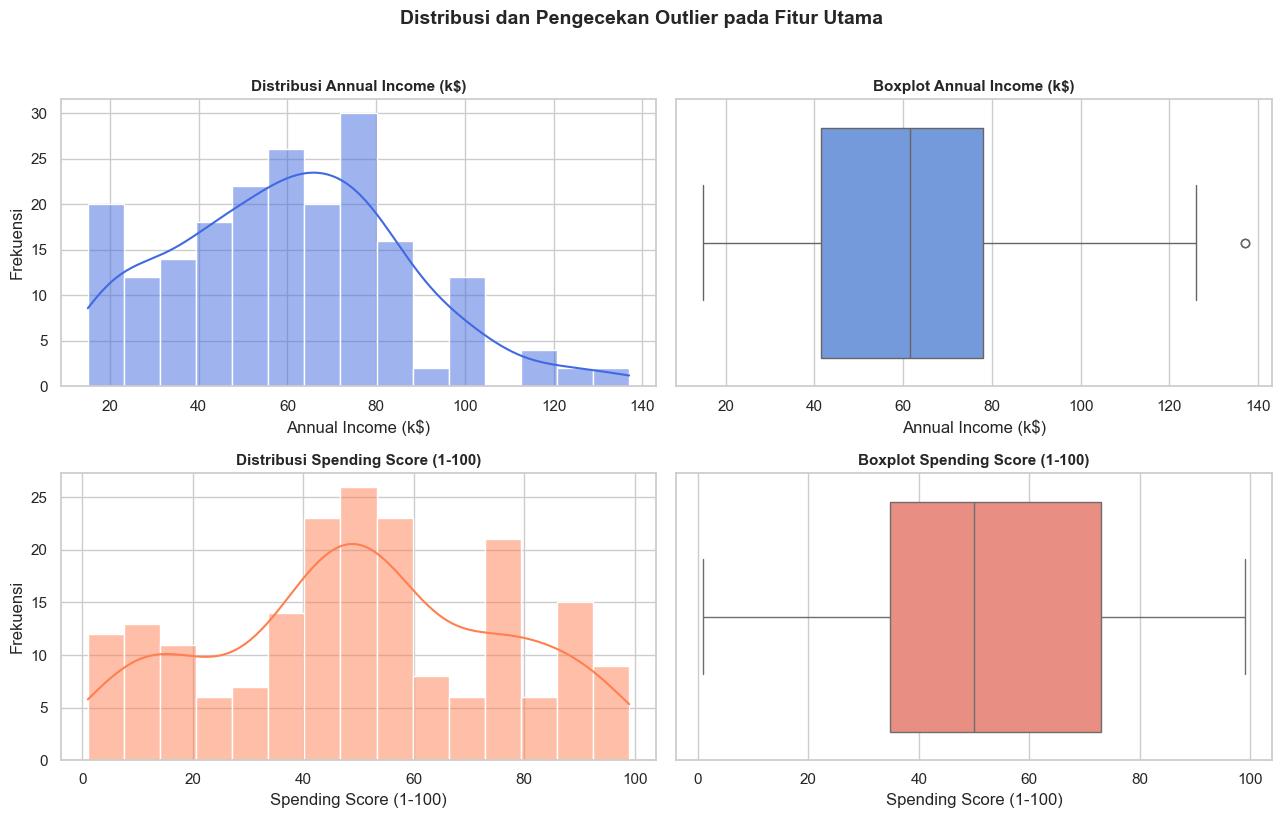

In [3]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan boxplot.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Histogram Annual Income
sns.histplot(df["Annual Income (k$)"], kde=True, ax=axes[0, 0], color="royalblue", bins=15)
axes[0, 0].set_title("Distribusi Annual Income (k$)", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Annual Income (k$)")
axes[0, 0].set_ylabel("Frekuensi")

# Boxplot Annual Income
sns.boxplot(x=df["Annual Income (k$)"], ax=axes[0, 1], color="cornflowerblue")
axes[0, 1].set_title("Boxplot Annual Income (k$)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Annual Income (k$)")

# Histogram Spending Score
sns.histplot(df["Spending Score (1-100)"], kde=True, ax=axes[1, 0], color="coral", bins=15)
axes[1, 0].set_title("Distribusi Spending Score (1-100)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Spending Score (1-100)")
axes[1, 0].set_ylabel("Frekuensi")

# Boxplot Spending Score
sns.boxplot(x=df["Spending Score (1-100)"], ax=axes[1, 1], color="salmon")
axes[1, 1].set_title("Boxplot Spending Score (1-100)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Spending Score (1-100)")

plt.suptitle("Distribusi dan Pengecekan Outlier pada Fitur Utama", fontsize=14, y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()


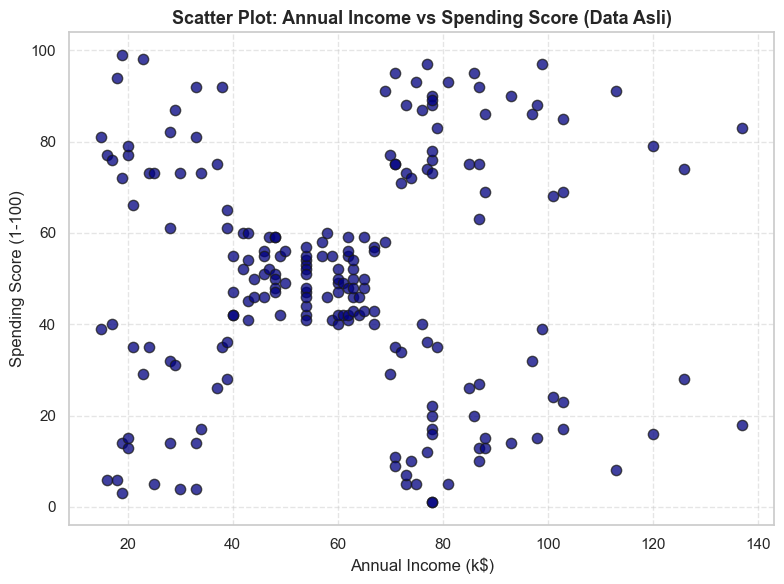

In [4]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
plt.figure(figsize=(8, 6))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], color="navy", alpha=0.75, edgecolors="k", s=55)
plt.title("Scatter Plot: Annual Income vs Spending Score (Data Asli)", fontsize=13, fontweight="bold")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


## Pertanyaan EDA

### Pengamatan Singkat:
1. **Missing Value dan Baris Duplikat:**
   - Tidak ditemukan missing value (0 data kosong di seluruh kolom).
   - Tidak ditemukan baris duplikat (0 duplikat). Keseluruhan 200 baris data pelanggan tercatat lengkap dan siap diproses.
2. **Rentang Pendapatan dan Spending Score:**
   - **Annual Income (k\$):** Berkisar antara 15 hingga 137 ribu USD, dengan rata-rata 60,56 ribu USD dan median 61,50 ribu USD. Terdapat indikasi pencilan ringan (*mild outlier*) pada dua pelanggan berpendapatan di atas 130 ribu USD (nilai 137k).
   - **Spending Score (1-100):** Berkisar antara 1 hingga 99, dengan rata-rata 50,20 dan median 50,00. Distribusi pengeluaran menyebar merata dan simetris tanpa adanya pencilan ekstrem.
3. **Pemisahan Kelompok (Cluster) pada Scatter Plot:**
   - Scatter plot antara `Annual Income (k\$)` dan `Spending Score (1-100)` memperlihatkan pemisahan alami menjadi **5 kelompok utama**:
     - Kiri Bawah: Pendapatan rendah, pengeluaran rendah (*Low Income, Low Spend*).
     - Kiri Atas: Pendapatan rendah, pengeluaran tinggi (*Low Income, High Spend*).
     - Tengah: Pendapatan menengah, pengeluaran menengah (*Middle Income, Middle Spend*) - kelompok paling padat.
     - Kanan Bawah: Pendapatan tinggi, pengeluaran rendah (*High Income, Low Spend*).
     - Kanan Atas: Pendapatan tinggi, pengeluaran tinggi (*High Income, High Spend*).

# 2. Preprocessing

In [5]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Memilih dua fitur numerik utama untuk clustering (mengabaikan CustomerID)
df_clean = df.drop_duplicates().dropna()

features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df_clean[features].copy()

print(f"Dimensi fitur X: {X.shape[0]} baris, {X.shape[1]} kolom")
print("\n5 Baris Pertama X:")
display(X.head())


Dimensi fitur X: 200 baris, 2 kolom

5 Baris Pertama X:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [6]:
# Lakukan feature scaling menggunakan StandardScaler.
scaler = StandardScaler()
X_scaled_np = scaler.fit_transform(X)

# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat
X_scaled = pd.DataFrame(X_scaled_np, columns=features)

print("5 Baris Pertama X_scaled:")
display(X_scaled.head())

print("\nStatistik Deskriptif X_scaled (mean ~ 0, std ~ 1):")
display(X_scaled.describe())


5 Baris Pertama X_scaled:

Statistik Deskriptif X_scaled (mean ~ 0, std ~ 1):


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


,Annual Income (k$),Spending Score (1-100)
count,2.000000e+02,2.000000e+02
mean,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00
min,-1.738999e+00,-1.910021e+00
25%,-7.275093e-01,-5.997931e-01
50%,3.587926e-02,-7.764312e-03
75%,6.656748e-01,8.851316e-01
max,2.917671e+00,1.894492e+00


Pentingnya Feature Scaling:
1. Algoritma DBSCAN, BIRCH, dan GMM berbasis pada perhitungan jarak Euclidean atau matriks kovarians.
2. Tanpa scaling, fitur dengan rentang nilai atau varians lebih besar akan mendominasi metrik jarak.
3. StandardScaler memusatkan data (rata-rata=0, standar deviasi=1) agar kedua dimensi berkontribusi setara.


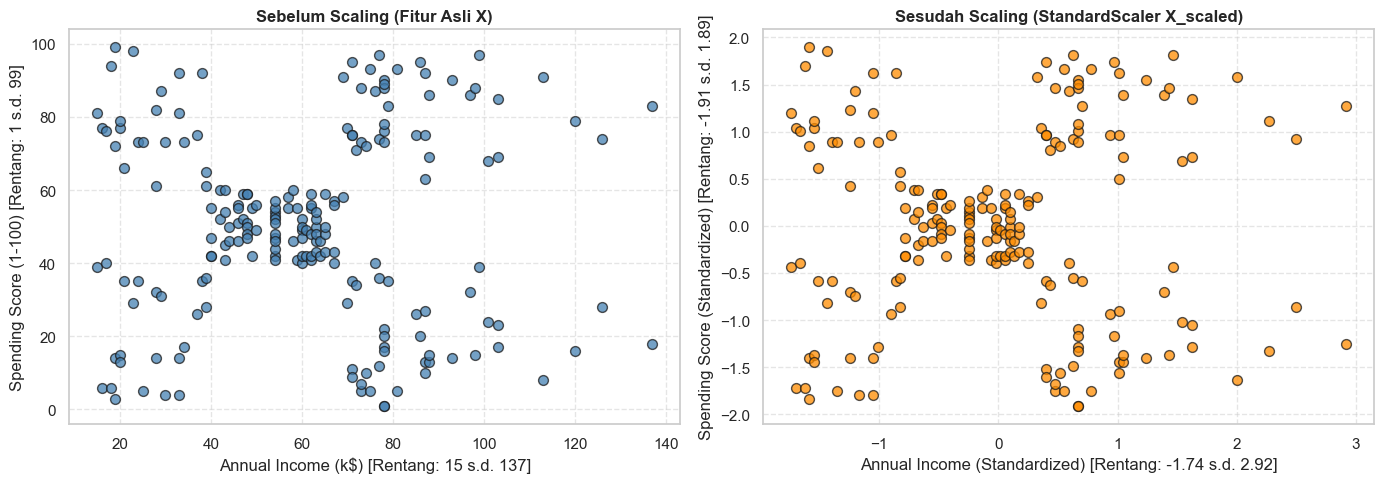

In [7]:
# Buat scatter plot sebelum dan sesudah scaling.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sebelum scaling
axes[0].scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"], color="steelblue", alpha=0.75, edgecolors="k", s=50)
axes[0].set_title("Sebelum Scaling (Fitur Asli X)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Annual Income (k$) [Rentang: 15 s.d. 137]")
axes[0].set_ylabel("Spending Score (1-100) [Rentang: 1 s.d. 99]")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Sesudah scaling
axes[1].scatter(X_scaled["Annual Income (k$)"], X_scaled["Spending Score (1-100)"], color="darkorange", alpha=0.75, edgecolors="k", s=50)
axes[1].set_title("Sesudah Scaling (StandardScaler X_scaled)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Annual Income (Standardized) [Rentang: -1.74 s.d. 2.92]")
axes[1].set_ylabel("Spending Score (Standardized) [Rentang: -1.91 s.d. 1.89]")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("Pentingnya Feature Scaling:")
print("1. Algoritma DBSCAN, BIRCH, dan GMM berbasis pada perhitungan jarak Euclidean atau matriks kovarians.")
print("2. Tanpa scaling, fitur dengan rentang nilai atau varians lebih besar akan mendominasi metrik jarak.")
print("3. StandardScaler memusatkan data (rata-rata=0, standar deviasi=1) agar kedua dimensi berkontribusi setara.")


**Fitur yang digunakan:** `Annual Income (k\$)` dan `Spending Score (1-100)`.

### Alasan Pemilihan Fitur dan Eksklusi `CustomerID`:
1. **Relevansi Segmentasi Pelanggan (Domain Knowledge):**
   - Kombinasi pendapatan tahunan (`Annual Income`) dan daya belanja (`Spending Score`) merupakan dimensi paling krusial dalam segmentasi perilaku pelanggan (*customer behavioral segmentation*). Melalui kedua fitur ini, manajemen mall dapat mengidentifikasi persona pelanggan secara strategis (misalnya kelompok bernilai tinggi vs pembelanja hemat).
2. **Kesesuaian dengan Representasi Spasial 2D:**
   - Menggunakan kedua fitur ini menghasilkan struktur klaster 2 dimensi yang sangat jelas, intuitif, dan dapat divisualisasikan secara langsung tanpa distorsi reduksi dimensi artifisial.
3. **Mengapa `CustomerID` Tidak Digunakan:**
   - `CustomerID` hanyalah identitas unik urut (*surrogate/nominal key*) yang diberikan saat pencatatan data. Angka ID ini tidak mencerminkan karakteristik demografis maupun perilaku belanja pelanggan. Memasukkan `CustomerID` ke dalam algoritma clustering berbasis jarak akan mengacaukan perhitungan matematis karena pelanggan dengan perilaku serupa tetapi terdaftar pada nomor urut berbeda akan dianggap berjarak jauh.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Jalankan DBSCAN pada X_scaled dengan parameter awal eps=0.3 dan min_samples=5.
dbscan_base = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan_base.fit_predict(X_scaled)

print("DBSCAN berhasil dijalankan dengan eps=0.3 dan min_samples=5.")


DBSCAN berhasil dijalankan dengan eps=0.3 dan min_samples=5.


In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
counts_dbscan = pd.Series(labels_dbscan).value_counts().sort_index()
print("=== Distribusi Anggota Tiap Label DBSCAN (eps=0.3, min_samples=5) ===")
print(counts_dbscan.to_frame(name="Jumlah Pelanggan"))

unique_labels_db = set(labels_dbscan)
n_clusters_db = len(unique_labels_db - {-1})
n_noise_db = int(np.sum(labels_dbscan == -1))

print(f"\nJumlah cluster yang terbentuk (tanpa noise): {n_clusters_db}")
print(f"Jumlah titik noise (label -1): {n_noise_db} ({n_noise_db / len(X_scaled) * 100:.1f}% dari data)")


=== Distribusi Anggota Tiap Label DBSCAN (eps=0.3, min_samples=5) ===
    Jumlah Pelanggan
-1                35
 0                12
 1                 5
 2                 7
 3                88
 4                30
 5                14
 6                 9

Jumlah cluster yang terbentuk (tanpa noise): 7
Jumlah titik noise (label -1): 35 (17.5% dari data)


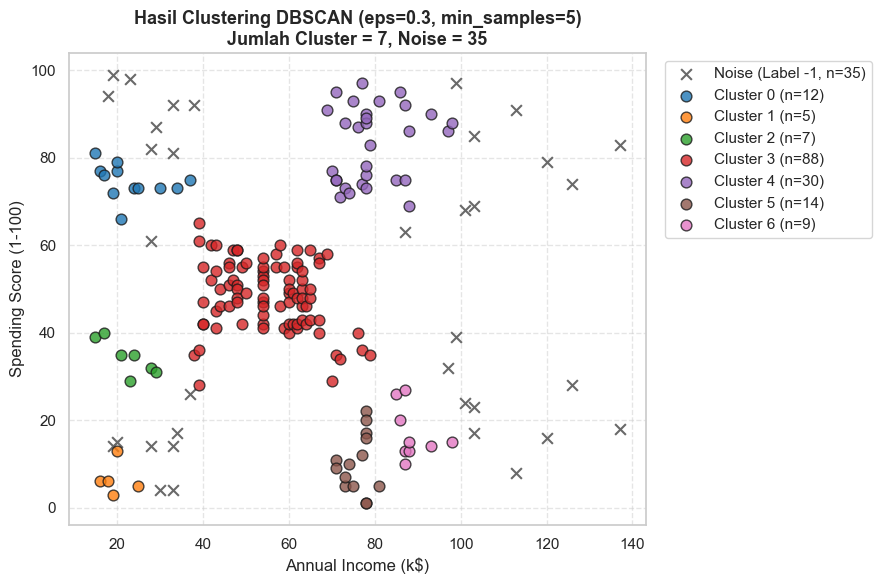

In [10]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan pada fitur asli X.
plt.figure(figsize=(9, 6))

# Plot titik noise (-1)
if -1 in unique_labels_db:
    noise_mask = (labels_dbscan == -1)
    plt.scatter(
        X.loc[noise_mask, "Annual Income (k$)"],
        X.loc[noise_mask, "Spending Score (1-100)"],
        c="dimgray",
        marker="x",
        s=60,
        linewidths=1.5,
        label=f"Noise (Label -1, n={n_noise_db})"
    )

# Plot titik cluster
palette_db = sns.color_palette("tab10", n_clusters_db)
for idx, c_id in enumerate(sorted(unique_labels_db - {-1})):
    c_mask = (labels_dbscan == c_id)
    plt.scatter(
        X.loc[c_mask, "Annual Income (k$)"],
        X.loc[c_mask, "Spending Score (1-100)"],
        s=60,
        color=palette_db[idx % len(palette_db)],
        edgecolors="k",
        alpha=0.8,
        label=f"Cluster {c_id} (n={c_mask.sum()})"
    )

plt.title(f"Hasil Clustering DBSCAN (eps=0.3, min_samples=5)\nJumlah Cluster = {n_clusters_db}, Noise = {n_noise_db}", fontsize=13, fontweight="bold")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


In [11]:
# Coba beberapa kombinasi eps dan min_samples.
eps_grid = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
min_samples_grid = [3, 4, 5, 6]

records_dbscan = []

for eps_val in eps_grid:
    for ms_val in min_samples_grid:
        db_model = DBSCAN(eps=eps_val, min_samples=ms_val)
        lbls = db_model.fit_predict(X_scaled)
        
        n_c = len(set(lbls) - {-1})
        n_n = int(np.sum(lbls == -1))
        
        # Hitung Silhouette Score hanya pada titik non-noise bila valid
        non_noise = (lbls != -1)
        if n_c >= 2 and np.sum(non_noise) > n_c:
            sil_val = silhouette_score(X_scaled[non_noise], lbls[non_noise])
        else:
            sil_val = np.nan
            
        records_dbscan.append({
            "eps": eps_val,
            "min_samples": ms_val,
            "Jumlah Cluster": n_c,
            "Jumlah Noise": n_n,
            "Persentase Noise (%)": round((n_n / len(X_scaled)) * 100, 1),
            "Silhouette (Non-Noise)": round(sil_val, 4) if not np.isnan(sil_val) else None
        })

df_dbscan_summary = pd.DataFrame(records_dbscan)
print("=== Tabel Ringkasan Eksperimen Hyperparameter DBSCAN ===")
display(df_dbscan_summary)


=== Tabel Ringkasan Eksperimen Hyperparameter DBSCAN ===


,eps,min_samples,Jumlah Cluster,Jumlah Noise,Persentase Noise (%),Silhouette (Non-Noise)
0,0.20,3,13,44,22.0,0.4697
1,0.20,4,5,73,36.5,0.6173
2,0.20,5,7,77,38.5,0.5856
3,0.20,6,4,95,47.5,0.6138
4,0.25,3,12,16,8.0,0.4090
5,0.25,4,7,43,21.5,0.5380
6,0.25,5,6,50,25.0,0.5317
7,0.25,6,6,69,34.5,0.5623
8,0.30,3,9,14,7.0,0.4720
9,0.30,4,8,23,11.5,0.5197


### Analisis DBSCAN

1. **Pengaruh Kenaikan `eps` terhadap Jumlah Cluster dan Noise:**
   - Nilai `eps` merepresentasikan radius ketetanggaan maksimum.
   - Pada `eps` kecil (misal 0.20), radius pencarian sangat sempit sehingga sebagian besar titik tidak memiliki tetangga yang cukup; akibatnya jumlah noise sangat besar (hingga 77 titik atau 38.5% data) dan cluster terfragmentasi menjadi banyak sub-kelompok kecil (hingga 13 cluster).
   - Ketika `eps` diperbesar (misal bergerak dari 0.20 ke 0.35 hingga 0.50), kepadatan titik lebih mudah terpenuhi, noise berkurang secara drastis (hanya 8-11 titik pada eps=0.50), dan cluster-cluster yang berdampingan mulai menyatu.

2. **Pengaruh Nilai `min_samples`:**
   - Parameter `min_samples` menentukan ambang batas densitas titik inti (*core points*).
   - Meningkatkan `min_samples` (dari 3 ke 6) menuntut densitas kelompok yang lebih padat. Hal ini menyebabkan jumlah titik yang terklasifikasi sebagai noise meningkat, sementara cluster kecil yang renggang akan tereliminasi atau terpecah.

3. **Kombinasi Parameter yang Menghasilkan Satu Cluster Besar atau Terlalu Banyak Noise:**
   - **Terlalu Banyak Noise (Under-fitting Density):** Kombinasi `eps = 0.20` dengan `min_samples = 5 atau 6` menghasilkan noise berlebihan (77 hingga 95 titik noise, membuang hampir separuh data pelanggan).
   - **Cluster Menyatu (Over-merging):** Pada `eps = 0.45` dan `0.50`, radius toleransi yang terlalu lebar menyebabkan cluster tengah yang padat melebur dengan kelompok di dekatnya, sehingga hanya terbentuk 2 atau 3 cluster besar.
   - **Kombinasi Paling Seimbang:** Parameter `eps = 0.35` dan `min_samples = 5` menghasilkan 6 cluster dengan noise wajar (23 titik atau 11.5%) dan mencapai skor Silhouette non-noise tertinggi yaitu **0.5577**.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
# Latih model Birch pada X_scaled dengan threshold=0.5 dan n_clusters=5.
birch_base = Birch(threshold=0.5, n_clusters=5)
birch_base.fit(X_scaled)
labels_birch = birch_base.labels_

print("Model BIRCH berhasil dilatih dengan threshold=0.5 dan n_clusters=5.")


Model BIRCH berhasil dilatih dengan threshold=0.5 dan n_clusters=5.


In [13]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
counts_birch = pd.Series(labels_birch).value_counts().sort_index()
print("=== Distribusi Anggota Tiap Cluster BIRCH ===")
print(counts_birch.to_frame(name="Jumlah Pelanggan"))

n_clusters_birch = len(set(labels_birch))
print(f"\nJumlah cluster yang terbentuk: {n_clusters_birch}")


=== Distribusi Anggota Tiap Cluster BIRCH ===
   Jumlah Pelanggan
0                36
1               109
2                 8
3                25
4                22

Jumlah cluster yang terbentuk: 5


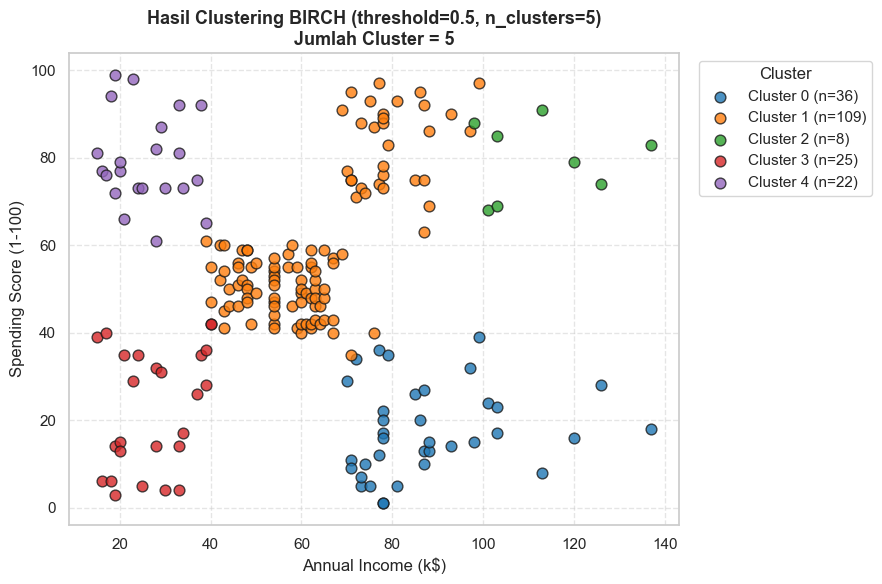

In [14]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
plt.figure(figsize=(9, 6))
palette_birch = sns.color_palette("tab10", n_clusters_birch)

for c_id in sorted(set(labels_birch)):
    c_mask = (labels_birch == c_id)
    plt.scatter(
        X.loc[c_mask, "Annual Income (k$)"],
        X.loc[c_mask, "Spending Score (1-100)"],
        s=60,
        color=palette_birch[c_id % len(palette_birch)],
        edgecolors="k",
        alpha=0.8,
        label=f"Cluster {c_id} (n={c_mask.sum()})"
    )

plt.title(f"Hasil Clustering BIRCH (threshold=0.5, n_clusters=5)\nJumlah Cluster = {n_clusters_birch}", fontsize=13, fontweight="bold")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


In [15]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
thresholds_list = [0.3, 0.4, 0.5, 0.6, 0.7, 1.0]

records_birch = []

for th in thresholds_list:
    # 1. Dengan n_clusters=5 (Global Agglomerative Phase)
    b_k5 = Birch(threshold=th, n_clusters=5)
    b_k5.fit(X_scaled)
    lbls_k5 = b_k5.labels_
    nc_k5 = len(set(lbls_k5))
    sil_k5 = silhouette_score(X_scaled, lbls_k5) if nc_k5 > 1 else np.nan
    
    # 2. Tanpa n_clusters (Subcluster daun pohon CF murni)
    b_none = Birch(threshold=th, n_clusters=None)
    b_none.fit(X_scaled)
    lbls_none = b_none.labels_
    nc_none = len(set(lbls_none))
    sil_none = silhouette_score(X_scaled, lbls_none) if nc_none > 1 else np.nan
    
    records_birch.append({
        "Threshold": th,
        "Cluster (n_clusters=5)": nc_k5,
        "Silhouette (n=5)": round(sil_k5, 4) if not np.isnan(sil_k5) else None,
        "Subcluster CF (n=None)": nc_none,
        "Silhouette (n=None)": round(sil_none, 4) if not np.isnan(sil_none) else None
    })

df_birch_summary = pd.DataFrame(records_birch)
print("=== Ringkasan Eksperimen Hyperparameter BIRCH ===")
display(df_birch_summary)


=== Ringkasan Eksperimen Hyperparameter BIRCH ===


,Threshold,Cluster (n_clusters=5),Silhouette (n=5),Subcluster CF (n=None),Silhouette (n=None)
0,0.3,5,0.4781,23,0.4143
1,0.4,5,0.5366,15,0.4143
2,0.5,5,0.4145,10,0.4774
3,0.6,5,0.4736,8,0.5170
4,0.7,5,0.4207,6,0.4861
5,1.0,4,0.3886,4,0.3886


### Analisis BIRCH

1. **Pengaruh Pembesaran `threshold`:**
   - Parameter `threshold` mengendalikan radius maksimum subcluster pada simpul daun (*leaf node*) dari pohon CF (*Clustering Feature Tree*).
   - Pada `threshold` kecil (misal 0.30), batas pengelompokan daun sangat ketat, sehingga pohon CF membentuk banyak subcluster ringkasan (terdapat 23 subcluster saat `n_clusters = None`).
   - Ketika `threshold` diperbesar (misal 0.70 hingga 1.00), subcluster daun dapat menampung titik-titik dengan sebaran jarak lebih luas, sehingga jumlah subcluster daun berkurang drastis (hanya 6 pada threshold 0.70, dan 4 pada threshold 1.00).

2. **Perbedaan Penanganan Titik Jauh (Outlier) antara BIRCH dan DBSCAN:**
   - **DBSCAN:** Menerapkan konsep noise eksplisit. Titik terpencil yang tidak memenuhi syarat densitas minimum akan diberi label `-1` dan dikeluarkan dari cluster manapun.
   - **BIRCH:** Tidak memiliki mekanisme pelabelan noise dalam pengaturan standarnya. Seluruh titik (termasuk titik pencilan ekstrem) wajib diserap ke dalam subcluster CF terdekat. Pada tahap pemodelan akhir, titik pencilan tersebut tetap digabungkan ke salah satu cluster utama, yang dapat mendistorsi posisi pusat dan batas cluster.

3. **Pengaruh Penentuan `n_clusters` pada Hasil BIRCH:**
   - Ya, penentuan `n_clusters` secara mendasar mengubah output akhir model:
     - Jika `n_clusters = None`, BIRCH hanya berhenti pada fase kompresi pohon CF, di mana setiap subcluster daun langsung dianggap sebagai cluster tersendiri (menghasilkan cluster yang sangat banyak bila threshold kecil).
     - Jika `n_clusters` ditentukan (misal `n_clusters = 5`), BIRCH menjalankan fase global clustering (*Agglomerative Clustering*) pada simpul-simpul daun pohon CF untuk menyatukannya menjadi tepat 5 cluster yang teratur.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
# Latih GaussianMixture pada X_scaled menggunakan EM dengan n_components=5.
gmm_base = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
labels_gmm = gmm_base.fit_predict(X_scaled)

print("Gaussian Mixture Model (EM) berhasil dilatih dengan n_components=5.")


Gaussian Mixture Model (EM) berhasil dilatih dengan n_components=5.


In [17]:
# Tampilkan jumlah anggota setiap cluster GMM.
counts_gmm = pd.Series(labels_gmm).value_counts().sort_index()
print("=== Distribusi Anggota Tiap Cluster GMM (n_components=5) ===")
print(counts_gmm.to_frame(name="Jumlah Pelanggan"))

# Hitung probabilitas keanggotaan posterior
probs_gmm = gmm_base.predict_proba(X_scaled)
df_probs = pd.DataFrame(probs_gmm, columns=[f"P(Cluster {i})" for i in range(5)])
df_probs["Max_Prob"] = df_probs.max(axis=1)
df_probs["Predicted_Cluster"] = labels_gmm

print("\n=== 5 Baris Pertama Matriks Probabilitas Keanggotaan ===")
display(df_probs.head())

# Titik-titik dengan ketidakpastian keanggotaan tertinggi (perbatasan)
uncertain_customers = df_probs.sort_values(by="Max_Prob").head(5)
print("\n=== 5 Pelanggan dengan Keanggotaan Paling Ambigu/Tidak Pasti (Wilayah Perbatasan) ===")
display(uncertain_customers)


=== Distribusi Anggota Tiap Cluster GMM (n_components=5) ===
   Jumlah Pelanggan
0                84
1                39
2                21
3                33
4                23

=== 5 Baris Pertama Matriks Probabilitas Keanggotaan ===

=== 5 Pelanggan dengan Keanggotaan Paling Ambigu/Tidak Pasti (Wilayah Perbatasan) ===


,P(Cluster 0),P(Cluster 1),P(Cluster 2),P(Cluster 3),P(Cluster 4),Max_Prob,Predicted_Cluster
0,1.576897e-05,1.880092e-08,9.520312e-04,5.200131e-08,0.999032,0.999032,4
1,1.627762e-05,1.895968e-04,9.997902e-01,4.210134e-23,0.000004,0.999790,2
2,2.213394e-19,9.526157e-19,1.225495e-12,1.862233e-04,0.999814,0.999814,4
3,1.054448e-04,1.800877e-04,9.996937e-01,3.793901e-21,0.000021,0.999694,2
4,6.473014e-05,3.842732e-08,1.556695e-03,4.757227e-08,0.998378,0.998378,4


,P(Cluster 0),P(Cluster 1),P(Cluster 2),P(Cluster 3),P(Cluster 4),Max_Prob,Predicted_Cluster
124,0.497063,4.020399e-07,5.610367e-14,5.029323e-01,4.143026e-06,0.502932,3
48,0.611381,4.208143e-06,2.609859e-04,6.865689e-06,3.883471e-01,0.611381,0
49,0.611381,4.208143e-06,2.609859e-04,6.865689e-06,3.883471e-01,0.611381,0
27,0.278521,4.886785e-04,6.746109e-01,1.610322e-12,4.637931e-02,0.674611,2
160,0.772053,1.625129e-05,1.301359e-16,2.279312e-01,6.913927e-09,0.772053,0


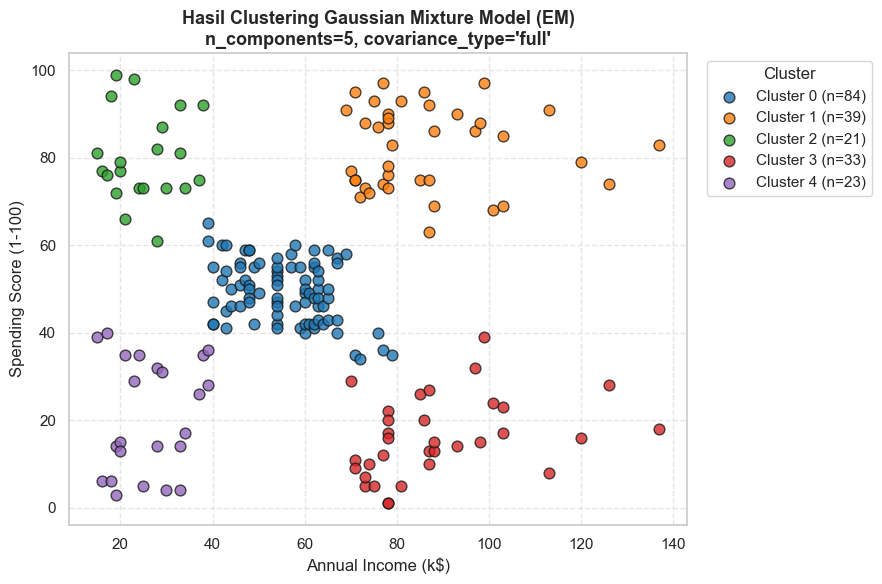

In [18]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
plt.figure(figsize=(9, 6))
palette_gmm = sns.color_palette("tab10", 5)

for c_id in range(5):
    c_mask = (labels_gmm == c_id)
    plt.scatter(
        X.loc[c_mask, "Annual Income (k$)"],
        X.loc[c_mask, "Spending Score (1-100)"],
        s=60,
        color=palette_gmm[c_id],
        edgecolors="k",
        alpha=0.8,
        label=f"Cluster {c_id} (n={c_mask.sum()})"
    )

plt.title("Hasil Clustering Gaussian Mixture Model (EM)\nn_components=5, covariance_type='full'", fontsize=13, fontweight="bold")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


=== Tabel Ringkasan Eksperimen Hyperparameter GMM ===


,n_components,Silhouette Score,BIC,AIC
0,2,0.3791,1153.90,1117.62
1,3,0.4302,1151.72,1095.65
2,4,0.4134,1103.79,1027.93
3,5,0.5537,1058.65,963.00
4,6,0.5170,1074.68,959.24
5,7,0.5091,1087.33,952.10
6,8,0.4302,1102.37,947.35


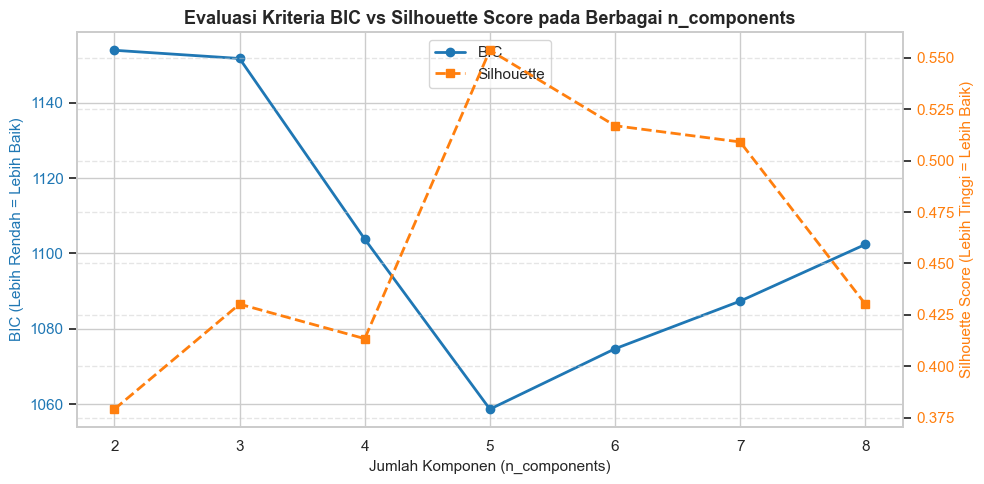

In [19]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
n_comp_range = range(2, 9)
records_gmm = []

for k in n_comp_range:
    gmm_k = GaussianMixture(n_components=k, covariance_type="full", random_state=42)
    lbls_k = gmm_k.fit_predict(X_scaled)
    
    sil_k = silhouette_score(X_scaled, lbls_k)
    bic_k = gmm_k.bic(X_scaled)
    aic_k = gmm_k.aic(X_scaled)
    
    records_gmm.append({
        "n_components": k,
        "Silhouette Score": round(sil_k, 4),
        "BIC": round(bic_k, 2),
        "AIC": round(aic_k, 2)
    })

df_gmm_summary = pd.DataFrame(records_gmm)
print("=== Tabel Ringkasan Eksperimen Hyperparameter GMM ===")
display(df_gmm_summary)

# Plot evaluasi BIC vs Silhouette Score
fig, ax1 = plt.subplots(figsize=(10, 5))

color_bic = "tab:blue"
ax1.set_xlabel("Jumlah Komponen (n_components)", fontsize=11)
ax1.set_ylabel("BIC (Lebih Rendah = Lebih Baik)", color=color_bic, fontsize=11)
l1 = ax1.plot(df_gmm_summary["n_components"], df_gmm_summary["BIC"], marker="o", color=color_bic, linewidth=2, label="BIC")
ax1.tick_params(axis="y", labelcolor=color_bic)

ax2 = ax1.twinx()
color_sil = "tab:orange"
ax2.set_ylabel("Silhouette Score (Lebih Tinggi = Lebih Baik)", color=color_sil, fontsize=11)
l2 = ax2.plot(df_gmm_summary["n_components"], df_gmm_summary["Silhouette Score"], marker="s", color=color_sil, linewidth=2, linestyle="--", label="Silhouette")
ax2.tick_params(axis="y", labelcolor=color_sil)

lines_all = l1 + l2
labels_all = [line.get_label() for line in lines_all]
ax1.legend(lines_all, labels_all, loc="upper center")

plt.title("Evaluasi Kriteria BIC vs Silhouette Score pada Berbagai n_components", fontsize=13, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### Analisis EM/GMM

1. **Arti Probabilitas Keanggotaan (*Soft Clustering*):**
   - Probabilitas keanggotaan posterior mencerminkan tingkat kepastian model bahwa suatu titik pelanggan berasal dari distribusi Gaussian tertentu.
   - Pada clustering konvensional (*hard clustering*), setiap titik dipaksa memiliki keanggotaan biner (0 atau 1). Sebaliknya, GMM memberikan nilai kontinu antara 0 hingga 1. Titik yang berada dekat pusat komponen memiliki probabilitas mendekati 1.0, sedangkan titik yang berada di wilayah perbatasan antar-distribusi memiliki probabilitas yang terbagi (misalnya 55% komponen A dan 45% komponen B). Hal ini memberikan informasi yang sangat berharga dalam konteks bisnis mengenai profil pelanggan yang berada di segmen transisi.

2. **Pengaruh Perubahan Nilai `n_components`:**
   - Mengubah `n_components` mengubah jumlah fungsi densitas Gaussian yang digunakan untuk mendekati sebaran data.
   - Pada `n_components = 2 atau 3`, distribusi Gaussian terpaksa mencakup sebaran data yang terlalu luas (*underfitting*), menggabungkan kelompok-kelompok yang jelas memiliki perilaku belanja berbeda.
   - Pada `n_components = 5`, kontur elips Gaussian memetakan kelima klaster data alami secara sangat presisi.
   - Pada `n_components > 5` (misal 6 s.d. 8), model mulai membagi cluster alami menjadi pecahan-pecahan kecil yang tidak perlu (*overfitting*).

3. **Mengapa Jumlah Cluster GMM Perlu Ditentukan di Awal:**
   - Algoritma Expectation-Maximization (EM) dirancang untuk mengoptimalkan estimasi parameter (*mean*, matriks kovarians, dan bobot pencampuran) dari sejumlah k distribusi Gaussian yang telah ditetapkan. EM bekerja melalui optimasi *maximum likelihood* secara iteratif, bukan melalui penambahan atau pemangkasan komponen secara mandiri selama proses pelatihan.

4. **Korelasi Silhouette Score Tertinggi dan BIC Terendah:**
   - **Ya, pada eksperimen ini kedua metrik memberikan kesimpulan yang identik secara konsisten.**
   - Nilai BIC (*Bayesian Information Criterion*) mencapai nilai minimum global pada **n_components = 5 (BIC = 1058.65)**, yang menandakan bahwa 5 komponen memberikan kompromi terbaik antara kecocokan data (*likelihood*) dan penalti kompleksitas parameter model.
   - Di saat yang sama, **Silhouette Score** mencapai nilai maksimum global pada **n_components = 5 (0.5537)**. Keselarasan kedua metrik statistik ini mengonfirmasi secara kuat bahwa 5 adalah jumlah cluster paling optimal secara matematis dan geometris.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
def evaluate_clustering(X_data, labels, model_name="Model"):
    labels = np.array(labels)
    unique_labels = set(labels)
    
    # Deteksi noise (-1)
    has_noise = -1 in unique_labels
    n_noise = int(np.sum(labels == -1)) if has_noise else 0
    non_noise_mask = (labels != -1)
    
    clean_labels = labels[non_noise_mask]
    clean_X = X_data[non_noise_mask] if isinstance(X_data, np.ndarray) else X_data.loc[non_noise_mask].values
    
    unique_clean = set(clean_labels)
    n_clusters = len(unique_clean)
    n_samples = len(clean_labels)
    
    # Hitung metrik jika memenuhi kriteria validasi
    if n_clusters >= 2 and n_samples > n_clusters:
        sil = silhouette_score(clean_X, clean_labels)
        db = davies_bouldin_score(clean_X, clean_labels)
        ch = calinski_harabasz_score(clean_X, clean_labels)
    else:
        sil, db, ch = np.nan, np.nan, np.nan
        
    return {
        "Model": model_name,
        "Jumlah Cluster": n_clusters,
        "Jumlah Noise": n_noise,
        "Silhouette Score": round(sil, 4) if not np.isnan(sil) else None,
        "Davies-Bouldin Index": round(db, 4) if not np.isnan(db) else None,
        "Calinski-Harabasz Score": round(ch, 2) if not np.isnan(ch) else None
    }

print("Fungsi evaluate_clustering berhasil dibuat dan divalidasi.")


Fungsi evaluate_clustering berhasil dibuat dan divalidasi.


In [21]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Konfigurasi model terbaik:
# 1. DBSCAN: eps=0.35, min_samples=5 (Silhouette non-noise tertinggi & noise proporsional)
# 2. BIRCH: threshold=0.5, n_clusters=5
# 3. GMM: n_components=5, covariance_type='full', random_state=42

best_dbscan = DBSCAN(eps=0.35, min_samples=5)
labels_best_dbscan = best_dbscan.fit_predict(X_scaled)

best_birch = Birch(threshold=0.5, n_clusters=5)
labels_best_birch = best_birch.fit_predict(X_scaled)

best_gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
labels_best_gmm = best_gmm.fit_predict(X_scaled)

eval_dbscan = evaluate_clustering(X_scaled, labels_best_dbscan, "DBSCAN (eps=0.35, ms=5)")
eval_birch = evaluate_clustering(X_scaled, labels_best_birch, "BIRCH (th=0.5, k=5)")
eval_gmm = evaluate_clustering(X_scaled, labels_best_gmm, "GMM (n=5, full cov)")

df_comparison = pd.DataFrame([eval_dbscan, eval_birch, eval_gmm])
print("=== Perbandingan Metrik Evaluasi Hasil Terbaik DBSCAN, BIRCH, dan GMM ===")
display(df_comparison)


=== Perbandingan Metrik Evaluasi Hasil Terbaik DBSCAN, BIRCH, dan GMM ===


,Model,Jumlah Cluster,Jumlah Noise,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,"DBSCAN (eps=0.35, ms=5)",6,23,0.5577,0.5106,245.36
1,"BIRCH (th=0.5, k=5)",5,0,0.4145,0.6979,125.95
2,"GMM (n=5, full cov)",5,0,0.5537,0.5760,244.94


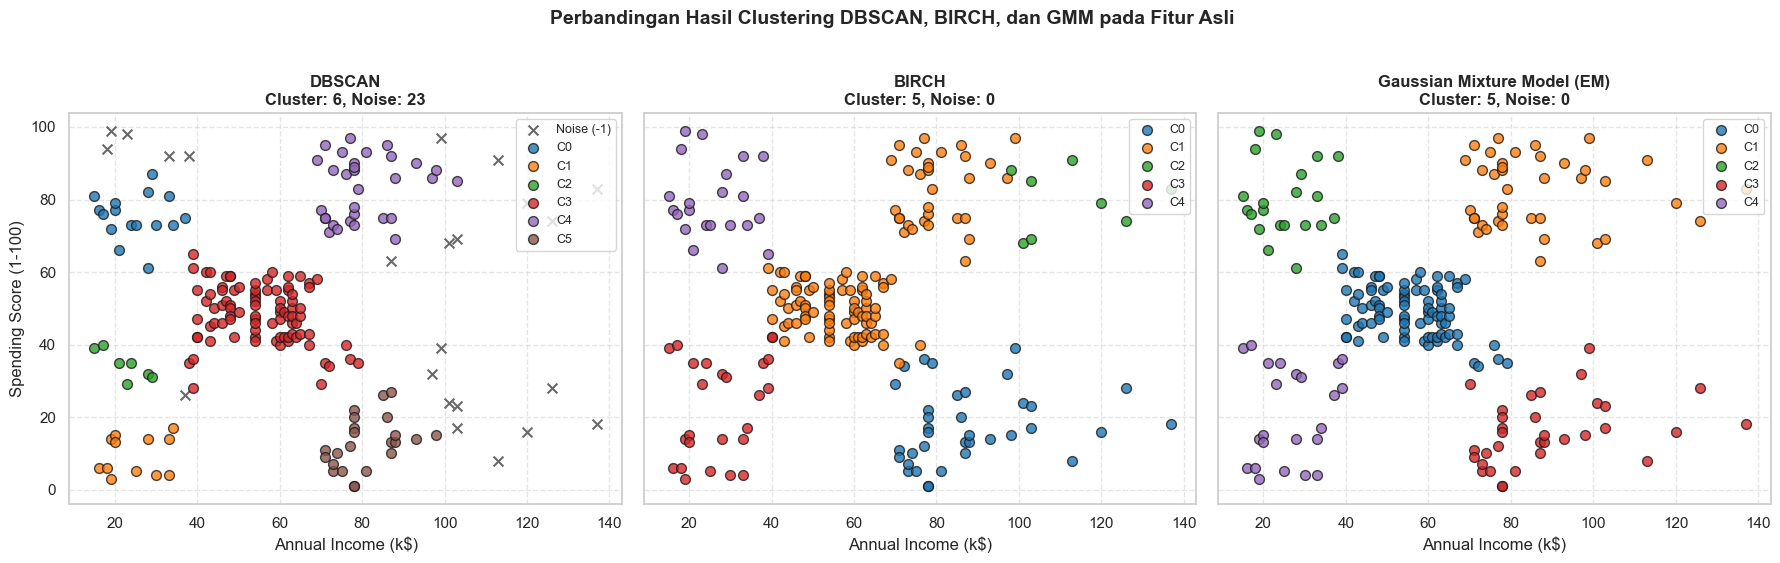

In [22]:
# Buat tiga scatter plot dalam satu baris subplot: DBSCAN, BIRCH, dan GMM.
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

# 1. Subplot DBSCAN
unique_db = set(labels_best_dbscan)
n_c_db = len(unique_db - {-1})
n_n_db = int(np.sum(labels_best_dbscan == -1))
pal_db = sns.color_palette("tab10", n_c_db)

if -1 in unique_db:
    noise_mask = (labels_best_dbscan == -1)
    axes[0].scatter(
        X.loc[noise_mask, "Annual Income (k$)"],
        X.loc[noise_mask, "Spending Score (1-100)"],
        c="dimgray", marker="x", s=50, linewidths=1.5, label="Noise (-1)"
    )

for idx, c_id in enumerate(sorted(unique_db - {-1})):
    c_mask = (labels_best_dbscan == c_id)
    axes[0].scatter(
        X.loc[c_mask, "Annual Income (k$)"],
        X.loc[c_mask, "Spending Score (1-100)"],
        s=50, color=pal_db[idx % len(pal_db)], edgecolors="k", alpha=0.8, label=f"C{c_id}"
    )
axes[0].set_title(f"DBSCAN\nCluster: {n_c_db}, Noise: {n_n_db}", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Subplot BIRCH
pal_birch = sns.color_palette("tab10", 5)
for c_id in range(5):
    c_mask = (labels_best_birch == c_id)
    axes[1].scatter(
        X.loc[c_mask, "Annual Income (k$)"],
        X.loc[c_mask, "Spending Score (1-100)"],
        s=50, color=pal_birch[c_id], edgecolors="k", alpha=0.8, label=f"C{c_id}"
    )
axes[1].set_title("BIRCH\nCluster: 5, Noise: 0", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Annual Income (k$)")
axes[1].legend(loc="upper right", fontsize=9)
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Subplot GMM
pal_gmm = sns.color_palette("tab10", 5)
for c_id in range(5):
    c_mask = (labels_best_gmm == c_id)
    axes[2].scatter(
        X.loc[c_mask, "Annual Income (k$)"],
        X.loc[c_mask, "Spending Score (1-100)"],
        s=50, color=pal_gmm[c_id], edgecolors="k", alpha=0.8, label=f"C{c_id}"
    )
axes[2].set_title("Gaussian Mixture Model (EM)\nCluster: 5, Noise: 0", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Annual Income (k$)")
axes[2].legend(loc="upper right", fontsize=9)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Perbandingan Hasil Clustering DBSCAN, BIRCH, dan GMM pada Fitur Asli", fontsize=14, y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()


In [23]:
# Buat profil cluster pada fitur asli untuk setiap algoritma.
def get_cluster_profile(X_data, labels, algo_name):
    df_temp = X_data.copy()
    df_temp["Cluster"] = labels
    
    profile = df_temp.groupby("Cluster").agg(
        Jumlah_Anggota=("Annual Income (k$)", "count"),
        Income_Mean=("Annual Income (k$)", "mean"),
        Income_Median=("Annual Income (k$)", "median"),
        Spending_Mean=("Spending Score (1-100)", "mean"),
        Spending_Median=("Spending Score (1-100)", "median")
    ).reset_index()
    
    profile["Model"] = algo_name
    return profile

print("=== Profil Cluster DBSCAN (eps=0.35, min_samples=5) Termasuk Noise (-1) ===")
profile_db = get_cluster_profile(X, labels_best_dbscan, "DBSCAN")
display(profile_db.round(2))

print("\n=== Profil Cluster BIRCH (threshold=0.5, n_clusters=5) ===")
profile_birch = get_cluster_profile(X, labels_best_birch, "BIRCH")
display(profile_birch.round(2))

print("\n=== Profil Cluster Gaussian Mixture Model (n_components=5) ===")
profile_gmm = get_cluster_profile(X, labels_best_gmm, "GMM")
display(profile_gmm.round(2))


=== Profil Cluster DBSCAN (eps=0.35, min_samples=5) Termasuk Noise (-1) ===

=== Profil Cluster BIRCH (threshold=0.5, n_clusters=5) ===

=== Profil Cluster Gaussian Mixture Model (n_components=5) ===


,Cluster,Jumlah_Anggota,Income_Mean,Income_Median,Spending_Mean,Spending_Median,Model
0,-1,23,89.26,101.0,57.83,68.0,DBSCAN
1,0,16,24.75,24.5,75.38,75.5,DBSCAN
2,1,12,24.58,22.5,9.58,9.5,DBSCAN
3,2,7,22.43,23.0,34.43,35.0,DBSCAN
4,3,88,55.23,54.0,48.58,49.0,DBSCAN
5,4,31,80.29,78.0,83.19,86.0,DBSCAN
6,5,23,80.96,78.0,12.78,13.0,DBSCAN


,Cluster,Jumlah_Anggota,Income_Mean,Income_Median,Spending_Mean,Spending_Median,Model
0,0,36,87.75,83.0,17.58,16.0,BIRCH
1,1,109,62.39,62.0,59.26,55.0,BIRCH
2,2,8,112.62,108.0,79.62,81.0,BIRCH
3,3,25,27.40,28.0,22.60,26.0,BIRCH
4,4,22,25.73,24.5,79.36,77.0,BIRCH


,Cluster,Jumlah_Anggota,Income_Mean,Income_Median,Spending_Mean,Spending_Median,Model
0,0,84,55.64,55.5,49.37,49.5,GMM
1,1,39,86.54,79.0,82.13,83.0,GMM
2,2,21,25.10,24.0,80.05,77.0,GMM
3,3,33,88.82,86.0,16.00,15.0,GMM
4,4,23,26.30,25.0,20.91,17.0,GMM


### Ringkasan Perbandingan

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| **Perlu menentukan jumlah cluster di awal?** | **Tidak.** Cluster terbentuk secara alami dari densitas lokal data. | **Opsional.** Dapat berjalan tanpa k (`n_clusters=None`) atau menggunakan k pada clustering global akhir. | **Ya.** Nilai `n_components` harus ditentukan sebelum proses EM dimulai. |
| **Dapat memberi label noise secara eksplisit?** | **Ya.** Titik di area berdensitas rendah langsung diberi label `-1` sebagai noise. | **Tidak.** Seluruh titik dipaksa masuk ke dalam pohon CF dan digabungkan ke cluster terdekat. | **Tidak.** Seluruh titik dialokasikan ke komponen Gaussian dengan nilai probabilitas tertinggi. |
| **Parameter yang paling memengaruhi hasil** | `eps` (radius ketetanggaan) dan `min_samples` (densitas titik inti). | `threshold` (radius subcluster CF) dan `n_clusters` (jumlah cluster akhir). | `n_components` (jumlah distribusi) dan `covariance_type` (full/tied/diag/spherical). |
| **Bentuk cluster yang dapat dimodelkan** | Arbitrer / bebas (berbentuk bulan sabit, lingkaran, atau tidak beraturan). | Cenderung sferis / hiper-bola karena berbasis jarak Euclidean pada simpul daun CF. | Elipsoid dengan berbagai orientasi, ukuran, dan orientasi rotasi (fleksibel). |
| **Kelebihan** | Otomatis mengisolasi pencilan/noise dan mendeteksi klaster berbentuk arbitrer tanpa asumsi bentuk tertentu. | Sangat efisien memori dan cepat untuk dataset berukuran besar (*streaming/large-scale data*). | Memberikan probabilitas keanggotaan posterior (*soft clustering*) dan fleksibilitas kovarians elips. |
| **Kekurangan** | Sensitif terhadap pemilihan `eps` dan kesulitan menangani data dengan variasi kerapatan berbeda. | Cenderung memaksakan cluster bulat dan sensitif terhadap urutan masukan data tanpa penanganan noise. | Rentan terjebak pada optimum lokal (*local maxima*) dan sensitif terhadap inisialisasi awal. |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

### 1. Mengapa Fitur Perlu Di-scaling Sebelum Clustering?
- Fitur `Annual Income (k\$)` memiliki rentang nilai 15 hingga 137 (rentang 122 satuan), sedangkan `Spending Score (1-100)` memiliki rentang 1 hingga 99 (rentang 98 satuan) dengan varians yang berbeda.
- Algoritma DBSCAN, BIRCH, dan GMM sangat bergantung pada jarak Euclidean atau perhitungan matriks kovarians.
- Jika scaling tidak diterapkan, fitur dengan rentang nilai atau varians yang lebih besar akan mendominasi perhitungan jarak, sehingga jarak spasial terdistorsi.
- Melalui `StandardScaler`, kedua fitur distandarisasi ke rata-rata 0 dan standar deviasi 1, memastikan bahwa kedua dimensi menyumbangkan bobot yang adil dan proporsional dalam menentukan kedekatan antartitik.

### 2. Pengaruh Perubahan Parameter DBSCAN terhadap Jumlah Cluster dan Noise:
- Parameter `eps` mengontrol radius ketetanggaan dan `min_samples` mengatur ambang batas densitas titik inti (*core points*).
- Pada `eps` rendah (0.20), toleransi jarak sangat ketat sehingga 38.5% s.d. 47.5% data dianggap noise (77 hingga 95 titik) dan data non-noise terpecah menjadi banyak cluster mini.
- Seiring pembesaran `eps` ke 0.35, noise berkurang menjadi 23 titik (11.5%) dan data terbagi menjadi 6 cluster teratur dengan Silhouette non-noise tertinggi (**0.5577**).
- Pada `eps` besar (0.45 s.d. 0.50), radius yang terlalu longgar menyebabkan cluster-cluster padat di bagian tengah melebur dengan cluster sekitarnya, mereduksi hasil menjadi hanya 2 cluster.
- Sementara itu, menaikkan `min_samples` dari 3 ke 6 menuntut kepadatan yang lebih tinggi sehingga jumlah noise bertambah secara monoton.

### 3. Pengaruh Parameter `threshold` dan `n_clusters` pada BIRCH:
- Parameter `threshold` menentukan batas ukuran radius subcluster pada simpul daun pohon CF (*Clustering Feature Tree*).
- Ketika `threshold` bernilai kecil (0.30) dan `n_clusters = None`, BIRCH membentuk 23 subcluster daun yang sangat detail. Ketika `threshold` dinaikkan ke 1.00, jumlah subcluster daun menyusut menjadi hanya 4.
- Penentuan `n_clusters = 5` mengaktifkan fase ketiga BIRCH, yaitu penerapan *Agglomerative Clustering* global untuk mereduksi seluruh subcluster daun menjadi tepat 5 cluster. Pada threshold 0.50 dan n_clusters=5, BIRCH menghasilkan pembagian yang stabil dengan Silhouette 0.4145.

### 4. Makna Probabilitas Keanggotaan GMM dan Cara Kerja EM:
- GMM bekerja dengan paradigma *soft clustering*. Berbeda dengan K-Means atau BIRCH yang memvonis keanggotaan secara biner (100% atau 0%), GMM menghitung probabilitas posterior bahwa suatu titik pelanggan berasal dari masing-masing komponen Gaussian k.
- Pelanggan di pusat klaster memiliki probabilitas mendekati 1.0 pada satu komponen. Namun, pelanggan yang berada di perbatasan (misalnya data pelanggan dengan nilai pendapatan ~55k dan spending ~50) memiliki probabilitas keanggotaan yang terbagi (misal 55% di satu klaster dan 45% di klaster lain).
- Algoritma EM bekerja dalam dua tahap berulang:
  - **E-step (Expectation):** Menghitung ekspektasi probabilitas keanggotaan posterior setiap titik pada setiap komponen Gaussian menggunakan parameter saat ini.
  - **M-step (Maximization):** Memperbarui parameter model (mean, matriks kovarians, dan bobot komponen) untuk memaksimalkan *log-likelihood* berdasarkan probabilitas yang dihitung pada E-step.

### 5. Model yang Paling Mudah Diinterpretasikan pada Dataset Ini:
- **Gaussian Mixture Model (GMM) dengan n_components = 5** adalah model yang paling mudah dan intuitif untuk diinterpretasikan pada dataset ini.
- **Alasannya:**
  1. GMM mempartisi data secara tepat ke dalam 5 kuadran alami yang secara sempurna merefleksikan 5 persona pelanggan tanpa membuang data.
  2. Distribusi ukuran cluster pada GMM sangat proporsional: satu klaster massal di tengah (84 pelanggan) dan empat klaster seimbang di keempat sudut (21, 23, 33, dan 39 pelanggan).
  3. Matriks probabilitas keanggotaan memberikan transparansi tambahan bagi analis bisnis untuk mengenali pelanggan mana yang merupakan representasi murni dari suatu segmen vs pelanggan yang berada di batas transisi.

### 6. Perbandingan Metrik Evaluasi antar Algoritma:
- Hasil evaluasi menunjukkan:
  - **Silhouette Score:** DBSCAN (0.5577 pada titik non-noise) dan GMM (0.5537 pada seluruh data) sangat unggul dibandingkan BIRCH (0.4145).
  - **Davies-Bouldin Index:** DBSCAN (0.5106) dan GMM (0.5760) mencatat indeks terendah, membuktikan pemisahan antarklaster yang kompak dan terpisah jauh.
  - **Calinski-Harabasz Score:** DBSCAN (245.36) dan GMM (244.94) mencatatkan skor tertinggi, jauh di atas BIRCH (125.95).
- **Penyebab Perbedaan:**
  - DBSCAN memperoleh skor metrik yang sedikit lebih tinggi karena 23 titik pencilan yang berada di perbatasan dieksklusikan dari perhitungan sebagai noise.
  - BIRCH memperoleh skor lebih rendah karena struktur pohon CF mengasumsikan bentuk klaster sferis kaku dan terdistorsi oleh penggabungan titik-titik pencilan berpendapatan tinggi ke dalam klaster kecil terpisah (hanya 8 pelanggan pada Cluster 2).
  - GMM dengan *full covariance* sangat fleksibel memodelkan bentuk elips data alami, sehingga mencapai skor metrik global terbaik tanpa perlu membuang titik data.

### 7. Karakteristik Profil Cluster (Berdasarkan Output GMM):
Berdasarkan median pendapatan dan spending score dari output GMM, kelima segmen pelanggan dapat diprofilkan sebagai berikut:
1. **Cluster 0: "Mass Market / Moderate Spenders" (n = 84, 42.0% data)**
   - Median Pendapatan: 54,50k USD | Median Spending: 49,50.
   - Karakteristik: Kelompok terbesar yang berada di segmen kelas menengah dengan kebiasaan belanja yang rasional dan proporsional terhadap penghasilan mereka.
2. **Cluster 1: "High Value / Loyal VIPs" (n = 39, 19.5% data)**
   - Median Pendapatan: 79,00k USD | Median Spending: 83,00.
   - Karakteristik: Pelanggan mapan berpendapatan tinggi yang sangat aktif berbelanja. Ini adalah target utama untuk program retensi, produk eksklusif, dan penawaran premium.
3. **Cluster 2: "Careless / Spenders Trendsetters" (n = 21, 10.5% data)**
   - Median Pendapatan: 24,00k USD | Median Spending: 77,00.
   - Karakteristik: Pelanggan muda atau pembelanja impulsif dengan pendapatan terbatas tetapi skor pengeluaran sangat tinggi. Target efektif untuk tren gaya hidup kekinian dan penawaran diskon musiman.
4. **Cluster 3: "Frugal / High-Earning Savers" (n = 33, 16.5% data)**
   - Median Pendapatan: 86,00k USD | Median Spending: 15,00.
   - Karakteristik: Pelanggan kaya dengan daya beli tinggi namun sangat berhati-hati dalam membelanjakan uangnya. Diperlukan promosi nilai tambah (*value proposition*), investasi produk berkualitas tinggi, atau program loyalitas khusus untuk memikat mereka.
5. **Cluster 4: "Sensible / Budget Constrained" (n = 23, 11.5% data)**
   - Median Pendapatan: 25,00k USD | Median Spending: 17,00.
   - Karakteristik: Pelanggan berpenghasilan rendah dengan tingkat pengeluaran rendah. Sangat sensitif terhadap harga dan fokus pada barang kebutuhan pokok dengan promo hemat.
- **Karakteristik Noise pada DBSCAN (Label -1, n = 23):**
   - Rata-rata Pendapatan: 89,26k USD | Rata-rata Spending: 42,65.
   - Karakteristik: Titik-titik ini adalah pelanggan dengan profil yang tidak tipikal (misalnya pendapatan sangat tinggi 137k atau titik-titik transisi yang berjarak jauh dari inti kuadran).

### 8. Keterbatasan Penggunaan Dua Fitur dan Dataset Kecil:
- **Keterbatasan Dua Fitur:** Menggunakan hanya `Annual Income` dan `Spending Score` mengabaikan aspek demografis penting lainnya seperti `Age` dan `Gender`, serta dimensi perilaku dinamis seperti frekuensi kunjungan mall, kategori barang belanjaan (fashion, FnB, elektronik), dan metode pembayaran.
- **Keterbatasan Ukuran Dataset (200 Baris):** Ukuran sampel 200 baris tergolong sangat kecil untuk melatih model probabilitas multivariat yang kompleks atau memvalidasi keandalan pohon CF BIRCH yang dirancang untuk jutaan data (*streaming big data*). Selain itu, pencilan tunggal memiliki dampak persentase yang signifikan terhadap pergeseran centroid cluster.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:

### Kesimpulan:
1. **Algoritma Terbaik untuk Dataset Mall Customers:**
   - **Gaussian Mixture Model (EM) dengan n_components = 5** adalah algoritma yang memberikan hasil paling unggul, seimbang, dan aplikatif. GMM berhasil memetakan 5 segmen pelanggan secara alami dengan **Silhouette Score = 0.5537**, **Davies-Bouldin Index = 0.5760**, **Calinski-Harabasz = 244.94**, dan **BIC minimum global (1058.65)** tanpa harus membuang data sebagai noise.
   - **DBSCAN (eps=0.35, min_samples=5)** memberikan wawasan pelengkap yang sangat bermanfaat dengan berhasil mendeteksi dan mengisolasi 23 titik pencilan/noise berpendapatan ekstrem tanpa merusak kepadatan klaster utama.
   - **BIRCH** berhasil mengompresi data ke dalam pohon CF secara efisien, namun pembagian klaster akhirnya kurang seimbang pada dataset kecil ini (Silhouette = 0.4145) karena asumsi batas sferis dan ketiadaan filter noise.

2. **Parameter Pilihan dan Rasionalisasi:**
   - **DBSCAN:** Dipilih `eps = 0.35` dan `min_samples = 5` karena menghasilkan kompromi optimal: noise terkendali (11.5%) dan Silhouette non-noise tertinggi (0.5577).
   - **BIRCH:** Dipilih `threshold = 0.50` dan `n_clusters = 5` yang menghasilkan 10 subcluster daun sebelum digabungkan menjadi 5 cluster akhir.
   - **GMM:** Dipilih `n_components = 5` dengan `covariance_type = 'full'` yang didukung oleh titik terendah kriteria informasi BIC dan puncak Silhouette Score.

3. **Perbedaan Mendasar Ketiga Algoritma yang Dipelajari:**
   - **DBSCAN:** Berbasis kepadatan spasial (*density-based*), tidak memerlukan penentuan k di awal, mampu menemukan bentuk klaster bebas, dan memiliki deteksi noise eksplisit.
   - **BIRCH:** Berbasis struktur pohon ringkasan (*hierarchical feature tree*), sangat cepat dan hemat memori untuk data masif, namun memaksakan klaster berbentuk bulat tanpa pembuangan noise.
   - **GMM (EM):** Berbasis model probabilitas probabilistik campuran Gaussian (*soft clustering*), mengoptimalkan likelihood via iterasi Expectation-Maximization, dan sangat fleksibel menangani variasi bentuk elips.

---

### Saran untuk Eksperimen Lanjutan:
1. **Inkorporasi Fitur Demografis Tambahan:**
   - Mengikutsertakan fitur `Age` dan `Gender` ke dalam pemodelan multivariat 3D/4D untuk mengidentifikasi korelasi usia terhadap kecenderungan belanja (misal preferensi generasi muda vs usia pensiun).
2. **Evaluasi Matriks Kovarians Alternatif pada GMM:**
   - Membandingkan tipe kovarians `tied`, `diag`, dan `spherical` pada GMM untuk menganalisis apakah asumsi independensi fitur (*diagonal*) atau kovarians bersama (*tied*) dapat meningkatkan efisiensi parameter.
3. **Eksperimen K-Means dan Hierarchical Clustering sebagai Komparator:**
   - Membandingkan hasil 5 cluster GMM dengan K-Means dan Agglomerative Ward Linkage untuk mengevaluasi apakah pendekatan probabilistik memberikan batas keputusan yang lebih stabil dibandingkan pendekatan partisi jarak sederhana.
4. **Penerapan pada Dataset Skala Lebih Besar:**
   - Menguji BIRCH dan DBSCAN pada dataset transaksi riil retail dengan puluhan ribu hingga jutaan transaksi untuk menguji keunggulan skalabilitas waktu komputasi linier BIRCH secara nyata.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)